# PHASE 3A — Unified Dataset Creation

## Mount Drive & Imports

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import pandas as pd
from tqdm import tqdm

Mounted at /content/drive


## Define Paths

In [ ]:
ROOT = "/content/drive/MyDrive/FYP_YOLO_Hand_Detection"

ROI_ROOT = f"{ROOT}/roi_images_v3"
UNIFIED_DIR = f"{ROOT}/unified_roi_dataset"

os.makedirs(UNIFIED_DIR, exist_ok=True)

## Create Unified Class-wise Folder Structure

In [ ]:
splits = ["train", "valid", "test"]

# Get class names from any split (train used here)
classes = os.listdir(os.path.join(ROI_ROOT, "train"))

for cls in classes:
    os.makedirs(os.path.join(UNIFIED_DIR, cls), exist_ok=True)

print("Classes found:", classes)

Classes found: ['Registrar', 'R-DBlock', 'AudiBlock', 'Exam', 'Block2', 'Block3', 'Block4', 'office', 'Block1']


## Merge ALL ROI Images into One Dataset

In [ ]:
import shutil

total_images = 0

for split in splits:
    split_path = os.path.join(ROI_ROOT, split)

    for cls in os.listdir(split_path):
        src_cls_path = os.path.join(split_path, cls)
        dst_cls_path = os.path.join(UNIFIED_DIR, cls)

        for img in tqdm(os.listdir(src_cls_path), desc=f"{split}/{cls}"):
            src_img = os.path.join(src_cls_path, img)
            dst_img = os.path.join(dst_cls_path, img)

            shutil.copy(src_img, dst_img)
            total_images += 1

print(f"✅ Unified dataset created with {total_images} ROI images")

test/Block2: 100%|██████████| 1/1 [00:00<00:00,  3.15it/s]

✅ Unified dataset created with 412 ROI images


In [ ]:
def extract_video_id(filename):
    # Example:
    # Registrar_4_mp4-0020_..._roi_v3.jpg → Registrar_4_mp4
    base = filename.split("_roi")[0]
    video_id = base.rsplit("-", 1)[0]
    return video_id

def extract_frame_index(filename):
    # Extract frame number after last dash
    return int(filename.split("-")[-1].split("_")[0])

In [ ]:
records = []

for cls in os.listdir(UNIFIED_DIR):
    cls_path = os.path.join(UNIFIED_DIR, cls)

    for img in os.listdir(cls_path):
        records.append({
            "class": cls,
            "video_id": extract_video_id(img),
            "frame_index": extract_frame_index(img),
            "image_path": os.path.join(cls_path, img)
        })

df = pd.DataFrame(records)
df.head()

,class,video_id,frame_index,image_path
0,Registrar,Registrar_2_mp4,13,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...
1,Registrar,Registrar_4_mp4,4,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...
2,Registrar,Registrar_5_mp4,13,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...
3,Registrar,Registrar_6_mp4,15,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...
4,Registrar,Registrar_4_mp4,20,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...


## Save Metadata to Drive

In [ ]:
META_PATH = f"{ROOT}/phase3_metadata.csv"
df.to_csv(META_PATH, index=False)

print("Metadata saved at:", META_PATH)
print("Total samples:", len(df))
print("Total videos:", df["video_id"].nunique())

Metadata saved at: /content/drive/MyDrive/FYP_YOLO_Hand_Detection/phase3_metadata.csv
Total samples: 412
Total videos: 30


# PHASE 3B — VIDEO-LEVEL SPLITTING

# Load Metadata

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

ROOT = "/content/drive/MyDrive/FYP_YOLO_Hand_Detection"
META_PATH = f"{ROOT}/phase3_metadata.csv"

df = pd.read_csv(META_PATH)

print("Total images:", len(df))
print("Total videos:", df["video_id"].nunique())
print("Classes:", df["class"].unique())

Total images: 412
Total videos: 30
Classes: ['Registrar' 'R-DBlock' 'AudiBlock' 'Exam' 'Block2' 'Block3' 'Block4'
 'office' 'Block1']


## Create VIDEO-LEVEL TABLE

In [ ]:
video_df = (
    df[["video_id", "class"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Video-level table shape:", video_df.shape)
video_df.head()

Video-level table shape: (30, 2)


,video_id,class
0,Registrar_2_mp4,Registrar
1,Registrar_4_mp4,Registrar
2,Registrar_5_mp4,Registrar
3,Registrar_6_mp4,Registrar
4,Registrar_3_mp4,Registrar


In [ ]:
print(video_df["class"].value_counts())

class
Registrar    6
Exam         6
office       6
R-DBlock     4
AudiBlock    3
Block1       2
Block2       1
Block4       1
Block3       1
Name: count, dtype: int64


## Stratified VIDEO Split (Train / Val / Test)

We’ll do:

70% Train

15% Validation

15% Test

### Shuffle videos within each class

In [ ]:
from sklearn.utils import shuffle

video_splits = []

for cls, group in video_df.groupby("class"):
    group = shuffle(group, random_state=42).reset_index(drop=True)
    video_splits.append(group)

video_df_shuffled = pd.concat(video_splits).reset_index(drop=True)

### Assign splits per class

Rule:

If class has 1 video → TRAIN only

If class has 2 videos → TRAIN + TEST

If class has ≥3 videos → TRAIN + VALID + TEST

In [ ]:
split_map = {}

for cls, group in video_df_shuffled.groupby("class"):
    vids = group["video_id"].tolist()
    n = len(vids)

    if n == 1:
        split_map[vids[0]] = "train"

    elif n == 2:
        split_map[vids[0]] = "train"
        split_map[vids[1]] = "test"

    else:
        split_map[vids[0]] = "train"
        split_map[vids[1]] = "valid"
        split_map[vids[2]] = "test"

        # any remaining → train
        for v in vids[3:]:
            split_map[v] = "train"

## Apply split back to all frames

In [ ]:
df["split"] = df["video_id"].map(split_map)

## Verify final split

In [ ]:
print("Video split counts:")
print(df[["video_id","split"]].drop_duplicates()["split"].value_counts())

print("\nClass coverage per split:")
print(pd.crosstab(df["class"], df["split"]))

Video split counts:
split
train    19
test      6
valid     5
Name: count, dtype: int64

Class coverage per split:
split      test  train  valid
class                        
AudiBlock     2      3      3
Block1        7      5      0
Block2        0     26      0
Block3        0     29      0
Block4        0     29      0
Exam         18     69     17
R-DBlock     12     37     12
Registrar    16     66     17
office        7     34      3


## Save Phase 3B Metadata

In [ ]:
PHASE3B_PATH = f"{ROOT}/phase3B_metadata.csv"
df.to_csv(PHASE3B_PATH, index=False)

print("✅ Phase 3B metadata saved (fixed split)")

✅ Phase 3B metadata saved (fixed split)


# PHASE 3C — CNN FEATURE EXTRACTION

## Mount Drive & Imports

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
from tqdm import tqdm

import torch
import torch.nn as nn
from torchvision import models, transforms
from PIL import Image

Mounted at /content/drive


## Paths & Load Metadata

In [ ]:
ROOT = "/content/drive/MyDrive/FYP_YOLO_Hand_Detection"

META_PATH = f"{ROOT}/phase3B_metadata.csv"
FEATURE_ROOT = f"{ROOT}/cnn_features"

os.makedirs(FEATURE_ROOT, exist_ok=True)

df = pd.read_csv(META_PATH)

print("Total images:", len(df))
print("Total videos:", df["video_id"].nunique())
print("Classes:", df["class"].unique())

Total images: 412
Total videos: 30
Classes: ['Registrar' 'R-DBlock' 'AudiBlock' 'Exam' 'Block2' 'Block3' 'Block4'
 'office' 'Block1']


## Load Pretrained CNN (ResNet50)

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
resnet.fc = nn.Identity()   # remove classifier
resnet = resnet.to(device)
resnet.eval()

print("ResNet50 loaded as feature extractor")

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 100MB/s]


ResNet50 loaded as feature extractor


## Image Preprocessing Pipeline

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std =[0.229, 0.224, 0.225]
    )
])

## Feature Extraction Loop (CORE CELL)

In [ ]:
feature_paths = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Extracting CNN features"):

    img_path = row["image_path"]
    cls = row["class"]
    split = row["split"]

    # Output directory
    out_dir = os.path.join(FEATURE_ROOT, split, cls)
    os.makedirs(out_dir, exist_ok=True)

    # Feature filename
    base = os.path.splitext(os.path.basename(img_path))[0]
    feat_path = os.path.join(out_dir, base + ".npy")

    # Load image
    img = Image.open(img_path).convert("RGB")
    img_tensor = transform(img).unsqueeze(0).to(device)

    # Extract features
    with torch.no_grad():
        feature = resnet(img_tensor).squeeze().cpu().numpy()  # (2048,)

    np.save(feat_path, feature)
    feature_paths.append(feat_path)

Extracting CNN features: 100%|██████████| 412/412 [04:39<00:00,  1.47it/s]


## Update Metadata & Save

In [ ]:
df["feature_path"] = feature_paths

FEATURE_META_PATH = f"{ROOT}/phase3C_feature_metadata.csv"
df.to_csv(FEATURE_META_PATH, index=False)

print("✅ Feature extraction complete!")
print("Metadata saved at:", FEATURE_META_PATH)
print("Total feature vectors:", len(df))

✅ Feature extraction complete!
Metadata saved at: /content/drive/MyDrive/FYP_YOLO_Hand_Detection/phase3C_feature_metadata.csv
Total feature vectors: 412


## Sanity Checks

In [ ]:
# Check one feature
sample_feat = np.load(df["feature_path"].iloc[0])
print("Feature shape:", sample_feat.shape)  # should be (2048,)

# Verify splits
print("\nSplit distribution:")
print(df["split"].value_counts())

print("\nClass distribution:")
print(df["class"].value_counts())

Feature shape: (2048,)

Split distribution:
split
train    298
test      62
valid     52
Name: count, dtype: int64

Class distribution:
class
Exam         104
Registrar     99
R-DBlock      61
office        44
Block3        29
Block4        29
Block2        26
Block1        12
AudiBlock      8
Name: count, dtype: int64


# PHASE 3D — Sequence Construction

## Load feature metadata

In [ ]:
import os
import numpy as np
import pandas as pd
from tqdm import tqdm

from torch.nn.utils.rnn import pad_sequence
import torch

ROOT = "/content/drive/MyDrive/FYP_YOLO_Hand_Detection"
FEATURE_META = f"{ROOT}/phase3C_feature_metadata.csv"

df = pd.read_csv(FEATURE_META)
print("Total frames:", len(df))
print("Total videos:", df["video_id"].nunique())
df.head()

Total frames: 412
Total videos: 30


,class,video_id,frame_index,image_path,split,feature_path
0,Registrar,Registrar_2_mp4,13,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...,train,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...
1,Registrar,Registrar_4_mp4,4,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...,valid,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...
2,Registrar,Registrar_5_mp4,13,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...,train,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...
3,Registrar,Registrar_6_mp4,15,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...,train,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...
4,Registrar,Registrar_4_mp4,20,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...,valid,/content/drive/MyDrive/FYP_YOLO_Hand_Detection...


## Build sequences per video

In [ ]:
sequences = []
labels = []
splits = []
video_ids = []

grouped = df.groupby("video_id")

for video_id, group in tqdm(grouped, desc="Building video sequences"):
    group = group.sort_values("frame_index")

    feature_list = []
    for _, row in group.iterrows():
        feature = np.load(row["feature_path"])
        feature_list.append(feature)

    if len(feature_list) < 2:
        continue  # skip very short videos

    sequence = np.stack(feature_list)  # (T, 2048)

    sequences.append(sequence)
    labels.append(group["class"].iloc[0])
    splits.append(group["split"].iloc[0])
    video_ids.append(video_id)

print("Total video sequences:", len(sequences))

Building video sequences: 100%|██████████| 30/30 [00:01<00:00, 18.48it/s]

Total video sequences: 30


## Pad sequences

In [ ]:
tensor_sequences = [
    torch.tensor(seq, dtype=torch.float32)
    for seq in sequences
]

padded_sequences = pad_sequence(
    tensor_sequences,
    batch_first=True
)

print("Padded shape:", padded_sequences.shape)

Padded shape: torch.Size([30, 31, 2048])


## Encode labels

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(labels)

print("Classes:", label_encoder.classes_)
print("Num classes:", len(label_encoder.classes_))

Classes: ['AudiBlock' 'Block1' 'Block2' 'Block3' 'Block4' 'Exam' 'R-DBlock'
 'Registrar' 'office']
Num classes: 9


## Split into Train / Val / Test

In [ ]:
X_train, y_train = [], []
X_val, y_val = [], []
X_test, y_test = [], []

for i, split in enumerate(splits):
    if split == "train":
        X_train.append(padded_sequences[i])
        y_train.append(encoded_labels[i])
    elif split == "valid":
        X_val.append(padded_sequences[i])
        y_val.append(encoded_labels[i])
    else:
        X_test.append(padded_sequences[i])
        y_test.append(encoded_labels[i])

X_train = torch.stack(X_train)
X_val   = torch.stack(X_val)
X_test  = torch.stack(X_test)

y_train = torch.tensor(y_train)
y_val   = torch.tensor(y_val)
y_test  = torch.tensor(y_test)

print("Train:", X_train.shape)
print("Valid:", X_val.shape)
print("Test :", X_test.shape)

Train: torch.Size([19, 31, 2048])
Valid: torch.Size([5, 31, 2048])
Test : torch.Size([6, 31, 2048])


# Phase 3E — BiLSTM Training

## Validate class coverage per split

In [ ]:
import pandas as pd

# df is the Phase 3 metadata with columns:
# class | video_id | frame_index | image_path | split | feature_path

print("🔹 Frames per split:")
print(df["split"].value_counts())

print("\n🔹 Video-level class coverage per split:")
video_level = df[["video_id", "class", "split"]].drop_duplicates()
print(pd.crosstab(video_level["class"], video_level["split"]))

print("\n🔹 Video count per class:")
print(video_level["class"].value_counts())

🔹 Frames per split:
split
train    298
test      62
valid     52
Name: count, dtype: int64

🔹 Video-level class coverage per split:
split      test  train  valid
class                        
AudiBlock     1      1      1
Block1        1      1      0
Block2        0      1      0
Block3        0      1      0
Block4        0      1      0
Exam          1      4      1
R-DBlock      1      2      1
Registrar     1      4      1
office        1      4      1

🔹 Video count per class:
class
Registrar    6
Exam         6
office       6
R-DBlock     4
AudiBlock    3
Block1       2
Block2       1
Block4       1
Block3       1
Name: count, dtype: int64


## Handle class imbalance

### Compute class weights

In [ ]:
import torch
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Get training labels at SEQUENCE (video) level
train_classes = [
    labels[i] for i, s in enumerate(splits) if s == "train"
]

train_encoded = label_encoder.transform(train_classes)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_encoded),
    y=train_encoded
)

class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("Class weights:")
for cls, w in zip(label_encoder.classes_, class_weights.cpu().numpy()):
    print(f"{cls:12s} → {w:.3f}")

Class weights:
AudiBlock    → 2.111
Block1       → 2.111
Block2       → 2.111
Block3       → 2.111
Block4       → 2.111
Exam         → 0.528
R-DBlock     → 1.056
Registrar    → 0.528
office       → 0.528


### Use weighted loss

In [ ]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

## Final BiLSTM Training + Evaluation

### Model definition

In [ ]:
class BiLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_classes):
        super().__init__()
        self.lstm = nn.LSTM(
            input_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, x):
        _, (hn, _) = self.lstm(x)
        hn = torch.cat((hn[-2], hn[-1]), dim=1)
        return self.fc(hn)

## Training with Early Stopping

In [ ]:
from torch.utils.data import Dataset, DataLoader

class GestureDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [ ]:
BATCH_SIZE = 4  # small batch is correct for video sequences

train_loader = DataLoader(
    GestureDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    GestureDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    GestureDataset(X_test, y_test),
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("✅ DataLoaders created")
print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

✅ DataLoaders created
Train batches: 5
Val batches: 2
Test batches: 2


In [ ]:
# ---- DEFINE MODEL ----
num_classes = len(label_encoder.classes_)

model = BiLSTM(
    input_dim=2048,
    hidden_dim=256,
    num_classes=num_classes
).to(device)

# ---- OPTIMIZER ----
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# ---- EARLY STOPPING PARAMS ----
patience = 5
best_val_loss = float("inf")
patience_counter = 0

MODEL_DIR = f"{ROOT}/lstm_model"
os.makedirs(MODEL_DIR, exist_ok=True)

EPOCHS = 120

# ---- TRAIN LOOP ----
for epoch in range(EPOCHS):

    # -------- TRAIN --------
    model.train()
    train_loss = 0.0

    for Xb, yb in train_loader:
        Xb, yb = Xb.to(device), yb.to(device)

        optimizer.zero_grad()
        outputs = model(Xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    # -------- VALID --------
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for Xb, yb in val_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            val_loss += criterion(model(Xb), yb).item()

    print(
        f"Epoch {epoch+1:03d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

    # -------- EARLY STOP --------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        patience_counter = 0
        torch.save(model.state_dict(), f"{MODEL_DIR}/best_bilstm.pt")
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print("🛑 Early stopping triggered")
            break

Epoch 001 | Train Loss: 11.2628 | Val Loss: 4.2364
Epoch 002 | Train Loss: 10.2977 | Val Loss: 4.1427
Epoch 003 | Train Loss: 9.9843 | Val Loss: 4.0549
Epoch 004 | Train Loss: 9.3008 | Val Loss: 3.9829
Epoch 005 | Train Loss: 9.0957 | Val Loss: 3.8580
Epoch 006 | Train Loss: 8.4507 | Val Loss: 3.7271
Epoch 007 | Train Loss: 8.0697 | Val Loss: 3.6051
Epoch 008 | Train Loss: 7.2699 | Val Loss: 3.4403
Epoch 009 | Train Loss: 6.8659 | Val Loss: 3.3432
Epoch 010 | Train Loss: 6.0702 | Val Loss: 3.1198
Epoch 011 | Train Loss: 5.7733 | Val Loss: 2.9596
Epoch 012 | Train Loss: 4.8020 | Val Loss: 2.7828
Epoch 013 | Train Loss: 4.4627 | Val Loss: 2.5456
Epoch 014 | Train Loss: 4.0042 | Val Loss: 2.4552
Epoch 015 | Train Loss: 3.5117 | Val Loss: 2.3182
Epoch 016 | Train Loss: 3.2645 | Val Loss: 2.0879
Epoch 017 | Train Loss: 2.6642 | Val Loss: 1.9786
Epoch 018 | Train Loss: 2.3277 | Val Loss: 1.8737
Epoch 019 | Train Loss: 2.0916 | Val Loss: 1.7798
Epoch 020 | Train Loss: 1.8629 | Val Loss: 1.666

## Test Evaluation
### Load best model

In [ ]:
model.load_state_dict(torch.load(f"{MODEL_DIR}/best_bilstm.pt"))
model.eval()

BiLSTM(
  (lstm): LSTM(2048, 256, batch_first=True, bidirectional=True)
  (fc): Linear(in_features=512, out_features=9, bias=True)
)

### Predict

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

y_true, y_pred = [], []

with torch.no_grad():
    for Xb, yb in test_loader:
        Xb = Xb.to(device)
        preds = torch.argmax(model(Xb), dim=1).cpu().numpy()
        y_true.extend(yb.numpy())
        y_pred.extend(preds)

### Correct classification report

In [ ]:
present_labels = sorted(set(y_true))
present_names = label_encoder.inverse_transform(present_labels)

print("Classes present in TEST set:", present_names)

print(
    classification_report(
        y_true,
        y_pred,
        labels=present_labels,
        target_names=present_names,
        zero_division=0
    )
)

Classes present in TEST set: ['AudiBlock' 'Block1' 'Exam' 'R-DBlock' 'Registrar' 'office']
              precision    recall  f1-score   support

   AudiBlock       1.00      1.00      1.00         1
      Block1       1.00      1.00      1.00         1
        Exam       1.00      1.00      1.00         1
    R-DBlock       1.00      1.00      1.00         1
   Registrar       1.00      1.00      1.00         1
      office       1.00      1.00      1.00         1

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



### Confusion Matrix

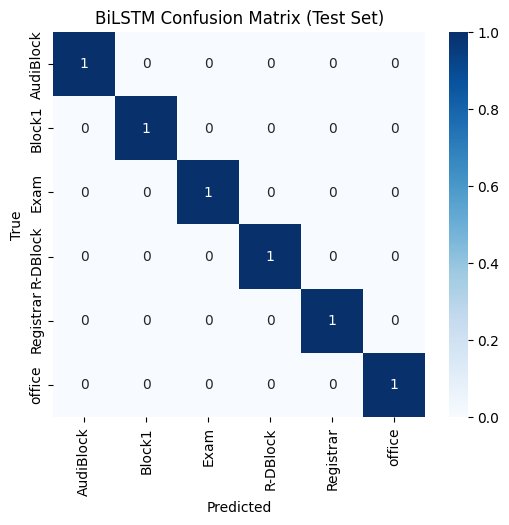

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred, labels=present_labels)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=present_names,
    yticklabels=present_names,
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("BiLSTM Confusion Matrix (Test Set)")
plt.show()